In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
df = pd.read_csv('/kaggle/input/datasets/vipullrathod/fish-market/Fish.csv')

df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (159, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    object 
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), object(1)
memory usage: 8.8+ KB

Missing Values:
Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

Statistical Summary:


,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


In [4]:
df = df[df['Weight'] > 0].copy()

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (158, 7)


In [5]:
X = df[['Length1', 'Length2', 'Length3', 'Height', 'Width']]

y = df['Weight']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (158, 5)
Target Shape: (158,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 126
Testing Samples: 32


In [7]:
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Training Shape:", X_train_poly.shape)
print("Testing Shape:", X_test_poly.shape)

Training Shape: (126, 20)
Testing Shape: (32, 20)


In [8]:
x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train_poly)
X_test_scaled = x_scaler.transform(X_test_poly)
print("X Scaling Completed")

X Scaling Completed


In [9]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Y Scaling Completed")

Y Scaling Completed


In [10]:
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_scaled,
    dtype=torch.float32
)

print("X Train:", X_train_tensor.shape)
print("Y Train:", y_train_tensor.shape)

X Train: torch.Size([126, 20])
Y Train: torch.Size([126, 1])


In [11]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True
)

print("Number of batches:", len(train_loader))

Number of batches: 126


In [12]:
torch.manual_seed(42)

model = nn.Linear(
    X_train_tensor.shape[1],
    1
)

criterion = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.9
)

print(model)

Linear(in_features=20, out_features=1, bias=True)


In [13]:
epochs = 200
losses = []

for epoch in range(epochs):

    model.train()

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        optimizer.step()

    model.eval()

    with torch.no_grad():
        epoch_predictions = model(X_train_tensor)
        epoch_loss = criterion(
            epoch_predictions,
            y_train_tensor
        ).item()

    losses.append(epoch_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {epoch_loss:.6f}"
        )

Epoch [20/200], Loss: 0.041527
Epoch [40/200], Loss: 0.026484
Epoch [60/200], Loss: 0.024016
Epoch [80/200], Loss: 0.140502
Epoch [100/200], Loss: 0.026771
Epoch [120/200], Loss: 0.032952
Epoch [140/200], Loss: 0.172525
Epoch [160/200], Loss: 0.096129
Epoch [180/200], Loss: 0.062372
Epoch [200/200], Loss: 0.031005


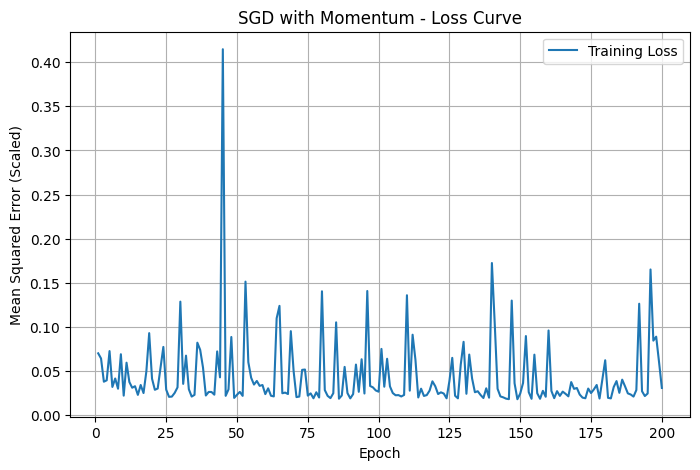

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    losses,
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Scaled)")
plt.title("SGD with Momentum - Loss Curve")

plt.legend()
plt.grid(True)
plt.show()

In [15]:
model.eval()

with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy()

y_pred = y_scaler.inverse_transform(
    y_pred_scaled
).flatten()

y_actual = y_test.to_numpy()

print("Predictions Completed")

Predictions Completed


In [16]:
mae = mean_absolute_error(y_actual, y_pred)

mse = mean_squared_error(y_actual, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_actual, y_pred)

print("SGD with Momentum Results")
print("--------------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

SGD with Momentum Results
--------------------------------------
MAE  : 55.3149
MSE  : 5942.1769
RMSE : 77.0855
R²   : 0.9557


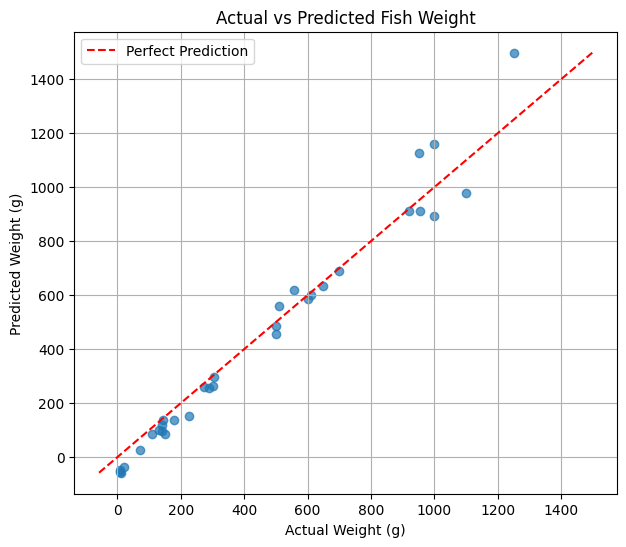

In [17]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.7
)

min_weight = min(y_actual.min(), y_pred.min())
max_weight = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_weight, max_weight],
    [min_weight, max_weight],
    'r--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Weight (g)")
plt.ylabel("Predicted Weight (g)")
plt.title("Actual vs Predicted Fish Weight")

plt.legend()
plt.grid(True)
plt.show()

In [18]:
results_df = pd.DataFrame({
    'Actual Weight': y_actual,
    'Predicted Weight': y_pred,
    'Absolute Error': np.abs(y_actual - y_pred)
})

display(results_df.head(10))

,Actual Weight,Predicted Weight,Absolute Error
0,300.0,264.117279,35.882721
1,140.0,96.677887,43.322113
2,510.0,558.495361,48.495361
3,19.7,-36.225739,55.925739
4,130.0,99.371918,30.628082
5,1000.0,892.632324,107.367676
6,145.0,135.703644,9.296356
7,180.0,138.278152,41.721848
8,225.0,153.524017,71.475983
9,1250.0,1497.829590,247.829590


In [19]:
results_df.to_csv(
    '/kaggle/working/sgd_predictions.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!
